In [1]:
import os

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [3]:
model_folder = "run_fibernet_20261116_164838_933228"

train_loss_path = os.path.abspath("./experiments/case_1/" + model_folder + "/losses.npy")

In [4]:
train_losses = np.load(train_loss_path)

In [5]:
train_losses

array([[0.00000000e+00, 2.10482076e-01, 2.07590580e-01, ...,
        1.13000917e+00, 3.48667297e+01, 2.01697171e-01],
       [1.00000000e+00, 1.90746993e-01, 1.84912756e-01, ...,
        1.22256899e+00, 3.11752796e+01, 2.18218327e-01],
       [2.00000000e+00, 1.78416073e-01, 1.85733795e-01, ...,
        1.35659289e+00, 2.73992119e+01, 2.42140457e-01],
       ...,
       [4.99810000e+04, 4.38426359e-05, 4.54748588e-05, ...,
        1.91387702e-02, 2.33739734e-01, 3.41611030e-03],
       [4.99820000e+04, 3.46973538e-05, 7.01765675e-05, ...,
        2.14711726e-02, 2.83022523e-01, 3.83242453e-03],
       [4.99830000e+04, 2.71547160e-05, 7.30157772e-05, ...,
        2.24318951e-02, 2.65826464e-01, 4.00390523e-03]], shape=(49984, 7))

In [6]:
iterations = train_losses[:, 0]
mse_v = train_losses[:, 1]
mse_w = train_losses[:, 2]
rel_v = train_losses[:, 3]
rel_w = train_losses[:, 4]
mae_v = train_losses[:, 5]
mae_w = train_losses[:, 6]

Text(0, 0.5, 'Relative L1 Error (V)')

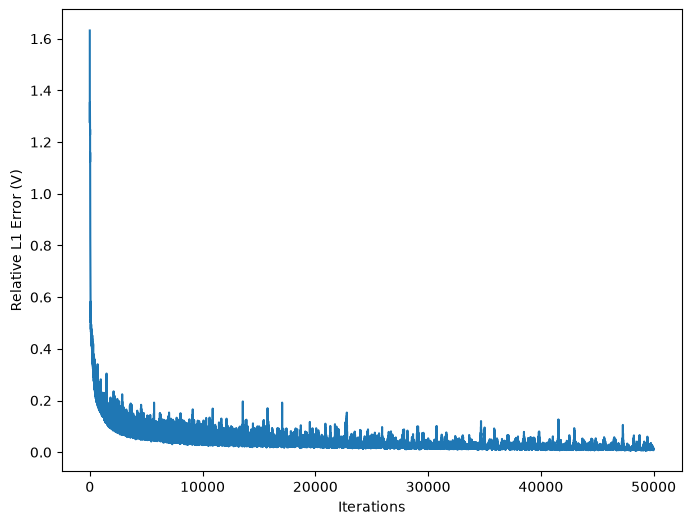

In [7]:
fig = plt.figure(figsize=(8, 6))
plt.plot(iterations, rel_v, label="REL v")

plt.xlabel("Iterations")
plt.ylabel("Relative L1 Error (V)")

In [8]:
rel_v.min()

np.float64(0.006549402140080929)

### Run PINN on test data

In [9]:
from case_data import CaseData, load_case_data, load_fields, resolve_case, case_dataset_path, resolve_cases
from scar_data_module import detect_device
from utils import load_config

from scar_data_module import ScarPINNDataModule
from pinn import PINN2D

In [10]:
DATA_SPLIT = {"train": [0.01, 0.015, 0.02, 0.03, 0.035, 0.04, 0.05, 0.055, 0.06, 0.07, 0.075, 0.08],
              "interpolation": [0.025, 0.045, 0.065],
              "extrapolation": [0.085, 0.09, 0.095, 0.1]}

In [18]:
device = detect_device()
case = "case_1"
model_folder = "run_fibernet_20261116_164838_933228"

config_path = os.path.abspath("./experiments/case_1/" + model_folder + "/config.yaml")

config = load_config(config_path)
dataset_path = case_dataset_path(case)

In [12]:
# Test on all vertices in the dataset
config['DATA']['sampling']['nx_test_slice'] = 1

In [13]:
dm = ScarPINNDataModule(config, case=case)
dm.setup_data()

Loading data
Using device: cuda
Dataset: data/scar_ep_case_1.h5
Geometry: case_1: 72344 vertices, 138524 collocation points, 10968 boundary points, 19 sims x 241 frames
Fields: vm (12, 241, 72344) (0.78 GiB x2), experiments [0.009999999776482582, 0.014999999664723873, 0.019999999552965164, 0.029999999329447746, 0.03500000014901161, 0.03999999910593033, 0.05000000074505806, 0.054999999701976776, 0.05999999865889549, 0.07000000029802322, 0.07500000298023224, 0.07999999821186066]
Training data: 209217824 samples, 51079 batches of size 4096, 72344 vertices, 241 time steps, 12 experiments
Collocation data: 634301396 samples, batch size 100
Boundary data: 50222472 samples, 502225 batches of size 100


In [14]:
training_indices = np.where([g_il_value in DATA_SPLIT['train'] for g_il_value in dm.case_data.g_il])[0]
interpolation_indices = np.where([g_il_value in DATA_SPLIT['interpolation'] for g_il_value in dm.case_data.g_il])[0]
extrapolation_indices = np.where([g_il_value in DATA_SPLIT['extrapolation'] for g_il_value in dm.case_data.g_il])[0]

In [19]:
vm_training, _ = load_fields(dataset_path, training_indices)
vm_interpolation, _ = load_fields(dataset_path, interpolation_indices)
vm_extrapolation, _ = load_fields(dataset_path, extrapolation_indices)

In [20]:
best_model_path = os.path.abspath("./experiments/case_1/" + model_folder + "/model_data_best.pth")

In [21]:
model = PINN2D(config, dm.mins, dm.maxes)
state = torch.load(best_model_path, map_location=device, weights_only=True)
model.load_state_dict(state)
model.eval()

Initializing PINN
Using CUDA device
PINN2D architecture:
Sequential(
  (0): Linear(in_features=4, out_features=4, bias=True)
  (1): Linear(in_features=4, out_features=256, bias=True)
  (2): Linear(in_features=256, out_features=256, bias=True)
  (3): Tanh()
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): Tanh()
  (6): Linear(in_features=256, out_features=256, bias=True)
  (7): Tanh()
  (8): Linear(in_features=256, out_features=256, bias=True)
  (9): Tanh()
  (10): Linear(in_features=256, out_features=256, bias=True)
  (11): Tanh()
  (12): Linear(in_features=256, out_features=256, bias=True)
  (13): Tanh()
  (14): Linear(in_features=256, out_features=256, bias=True)
  (15): Tanh()
  (16): Linear(in_features=256, out_features=256, bias=True)
  (17): Tanh()
  (18): Linear(in_features=256, out_features=256, bias=True)
  (19): SiLU()
  (20): Linear(in_features=256, out_features=2, bias=True)
)


PINN2D(
  (layer_norm): Linear(in_features=4, out_features=4, bias=True)
  (model): Sequential(
    (0): Linear(in_features=4, out_features=4, bias=True)
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): Tanh()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): Tanh()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): Tanh()
    (8): Linear(in_features=256, out_features=256, bias=True)
    (9): Tanh()
    (10): Linear(in_features=256, out_features=256, bias=True)
    (11): Tanh()
    (12): Linear(in_features=256, out_features=256, bias=True)
    (13): Tanh()
    (14): Linear(in_features=256, out_features=256, bias=True)
    (15): Tanh()
    (16): Linear(in_features=256, out_features=256, bias=True)
    (17): Tanh()
    (18): Linear(in_features=256, out_features=256, bias=True)
    (19): SiLU()
    (20): Linear(in_features=256, out_features=2, bias=True)
  )
)

In [22]:
x, y = dm.dataset.x, dm.dataset.y

In [23]:
vm_interpolation.shape

(3, 241, 72344)

In [24]:
dm.dataset.t.shape

(241,)

In [25]:
indices = extrapolation_indices
# indices = interpolation_indices
# indices = training_indices

n_vertices = len(x)
n_timesteps = len(dm.dataset.t)
total = n_vertices * n_timesteps

pred = np.empty((len(indices), total), dtype=np.float32)
with torch.no_grad():
    for i in range(len(indices)):
        for start in range(0, total, 10000):
            end = min(start + 10000, total)
            flat = np.arange(start, end)

            time_idx = flat // n_vertices
            vertex_idx = flat % n_vertices

            X = np.column_stack((
                x[vertex_idx],
                y[vertex_idx],
                dm.dataset.t[time_idx],
                np.full_like(flat, dm.case_data.g_il[indices[i]])
            )).astype(np.float32)

            X = torch.from_numpy(X).to(device)
            pred[i, flat] = model.predict(X).squeeze(1).cpu().numpy()
        
    pred = pred.reshape((len(indices), n_timesteps, n_vertices))

In [26]:
vm = vm_extrapolation
# vm = vm_interpolation
# vm = vm_training

errors = np.empty(len(indices), dtype=np.float32)

for i in range(len(indices)):
    abs_sum = np.sum(np.abs(vm[i] - pred[i]))
    v_sum = np.sum(np.abs(vm[i]))
    errors[i] = abs_sum / v_sum

In [27]:
errors

array([0.11895522, 0.12118423, 0.12330053, 0.12531379], dtype=float32)

In [28]:
errors.mean()

np.float32(0.12218844)

In [29]:
# Reshape predictions and ground truth to (n_timesteps, n_vertices, n_samples)
pred_reshaped = pred.reshape((n_timesteps, n_vertices, len(indices)))
vm_reshaped = vm.reshape((n_timesteps, n_vertices, len(indices)))

In [30]:
# Save preds and ground truth to .npy files
np.save(os.path.abspath("./data/vm_PINN.npy"), pred_reshaped)
np.save(os.path.abspath("./data/vm_variation_scar_full.npy"), vm_reshaped)

In [49]:
from utils import get_mesh_data
import matplotlib.tri as tri

ANIM_OUTDIR = os.path.abspath("./results/animations/ingvild")
EXPERIMENT_GILS = np.linspace(0.01, 0.1, 19)


def _ensure_dir(path):
    os.makedirs(path, exist_ok=True)

def _triangulation_from_utils():
    vertices, triangles, _ = get_mesh_data()
    vertices = vertices * 1e-3
    triang = tri.Triangulation(vertices[:, 0], vertices[:, 1], triangles)
    return vertices, triang

def _apply_axes_style(ax, zoom):
    if zoom is not None:
        ax.set_ylim(zoom[0], zoom[1])
        ax.set_xlim(zoom[2], zoom[3])
    ax.set_xlabel("x [mm]")
    ax.set_ylabel("y [mm]")
    ax.set_aspect("equal")

def animation_PINN_FEM(exp_idx,
                       *,
                       zoom=None,
                       fps=20,
                       bitrate=1000,
                       filename=None):
    """
    Side-by-side animation of PINN vs FEM for experiment index exp_idx.
    Uses saved arrays: ./data/vm_PINN.npy and ./data/vm_variation_scar_full.npy
    """
    _ensure_dir(ANIM_OUTDIR)
    vertices, triang = _triangulation_from_utils()

    v_FEM_all  = np.load("./data/vm_variation_scar_full.npy")  # (T, V, E)
    v_PINN_all = np.load("./data/vm_PINN.npy")                  # (T, V, E)

    v_FEM  = v_FEM_all[:, :, exp_idx]
    v_PINN = v_PINN_all[:, :, exp_idx]
    g_il = EXPERIMENT_GILS[exp_idx]

    T_len, V_count = v_FEM.shape
    assert v_PINN.shape == (T_len, V_count)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10))

    im1 = ax1.tripcolor(triang, v_PINN[0, :], shading="gouraud", cmap=plt.cm.cividis, vmin=-80, vmax=20)
    im2 = ax2.tripcolor(triang, v_FEM[0,  :], shading="gouraud", cmap=plt.cm.cividis, vmin=-80, vmax=20)


    cbar = fig.colorbar(im2, ax=[ax1, ax2],  # span both axes
                    orientation="vertical",
                    fraction=0.046, pad=0.04)
    cbar.set_label(r"$V_m$ [mV]")
    _apply_axes_style(ax1, zoom)
    _apply_axes_style(ax2, zoom)
    ax1.set_title(r"$\bf{PINN}$: $g_{il}$="+f"{g_il:.3f}S/m", fontsize=20)
    ax2.set_title(r"$\bf{FEM}$: $g_{il}$="+f"{g_il:.3f}S/m",  fontsize=20)

    def update(frame):
        v_pred = v_PINN[frame, :]
        v_true = v_FEM[frame,  :]

        im1.set_array(v_pred)
        im2.set_array(v_true)

        # Per-frame RL1 (consistent with your older title behavior)
        denom = np.sum(np.abs(v_true))
        RL1 = (np.sum(np.abs(v_true - v_pred)) / denom) if denom > 0 else np.nan

        ax1.set_title(r"$\bf{PINN}$: $g_{il}$="+f"{g_il:.3f}S/m" + f"\n t={frame*5:.0f} ms, RL1={RL1:.3f}", fontsize=20)
        ax2.set_title(r"$\bf{FEM}$: $g_{il}$="+f"{g_il:.3f}S/m"  + f"\n t={frame*5:.0f} ms",               fontsize=20)
        return im1, im2

    ani = animation.FuncAnimation(fig, update, frames=T_len, interval=1, blit=False)

    if filename is None:
        filename = f"S{exp_idx+1}_vm_pinn_fem_gil_{g_il:.3f}.mp4"
    outpath = os.path.join(ANIM_OUTDIR, filename)
    ani.save(outpath, writer=animation.FFMpegWriter(fps=fps, codec=ANIM_CODEC, bitrate=bitrate))
    plt.close(fig)

ValueError: The length of c must match either the number of points or the number of triangles

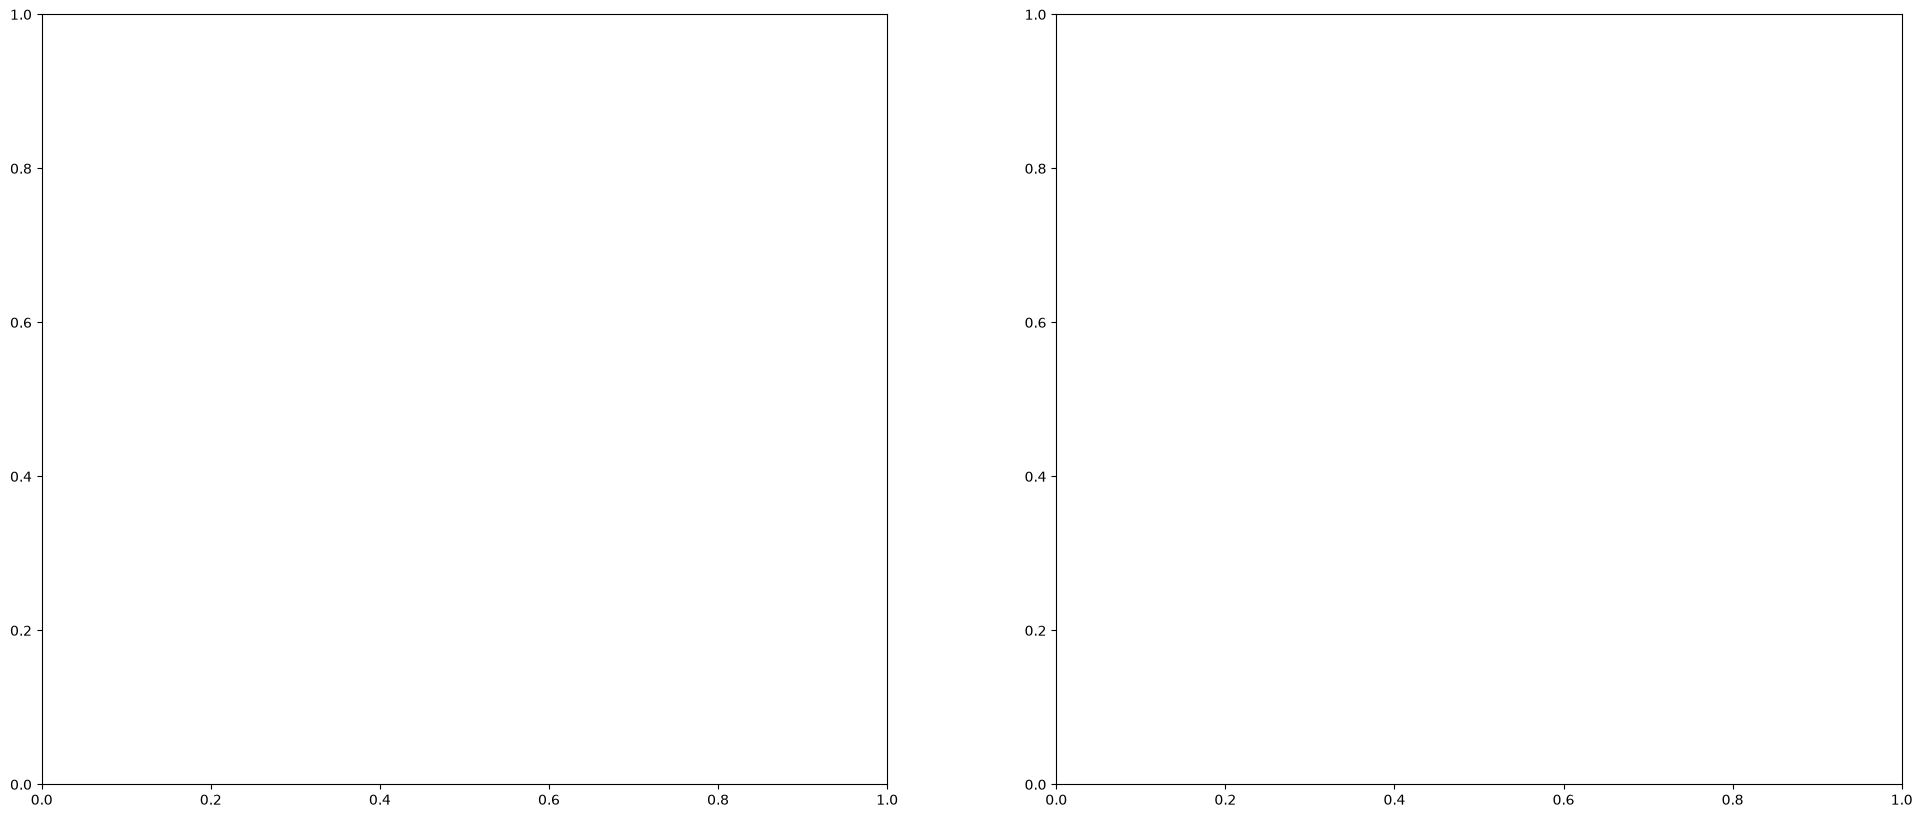

In [50]:
animation_PINN_FEM(0)